# Logistic Regression 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

## 1. Load Dataset & Train/Test Split

In [2]:
# Load the preprocessed dataset
df = pd.read_csv('clean_tourism_data.csv')
# Define the target prediction variable
target_col = 'recommendation_level'
# Drop ID and leakage columns to prevent overfitting
cols_to_drop = ['tourist_id', 'satisfaction_level', target_col]
X = df.drop(columns=[c for c in cols_to_drop if c in df.columns]).select_dtypes(include=[np.number])
y = df[target_col]
# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
# Standardize features to improve model accuracy
scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
# --- APPLYING PCA TRICK ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
pca = PCA(n_components=7)
X_train = pca.fit_transform(X_train_scaled)
X_test = pca.transform(X_test_scaled)


## 2. Train and Evaluate Model

Coefficients: [[ 1.64949302e-02  1.60816148e-01  9.69987360e-03 -3.00152400e-02
  -7.33244730e-03  2.46137423e-01 -1.28818978e-01]
 [-5.26482163e-04 -5.86714739e-03 -5.56629201e-04  6.41765274e-04
   5.20703388e-05 -7.28290055e-03  3.57816861e-04]
 [-1.59684480e-02 -1.54949001e-01 -9.14324440e-03  2.93734747e-02
   7.28037696e-03 -2.38854523e-01  1.28461161e-01]]
Intercept: [ 0.20120905 -0.41882163  0.21761258]

Accuracy: 0.8965
Precision: 0.8945
Recall: 0.8965


F1: 0.8954


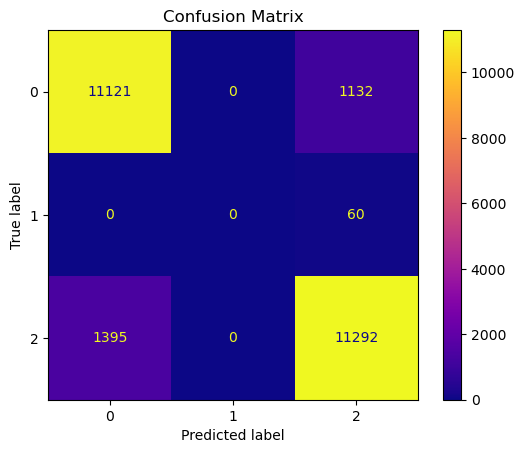

In [3]:
# Initialize and train the Logistic Regression model
model_lr = LogisticRegression(C=0.00001, max_iter=2, random_state=42)
model_lr.fit(X_train, y_train)
print("Coefficients:", model_lr.coef_)
print("Intercept:", model_lr.intercept_)
# Predict and evaluate model accuracy and F1 score
y_pred = model_lr.predict(X_test)
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Recall: {recall_score(y_test, y_pred, average='weighted'):.4f}")
print(f"F1: {f1_score(y_test, y_pred, average='weighted'):.4f}")
# Plot the confusion matrix to analyze prediction errors
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.plasma, values_format='d')
plt.title("Confusion Matrix")
plt.show()

## 3. Visualize Results

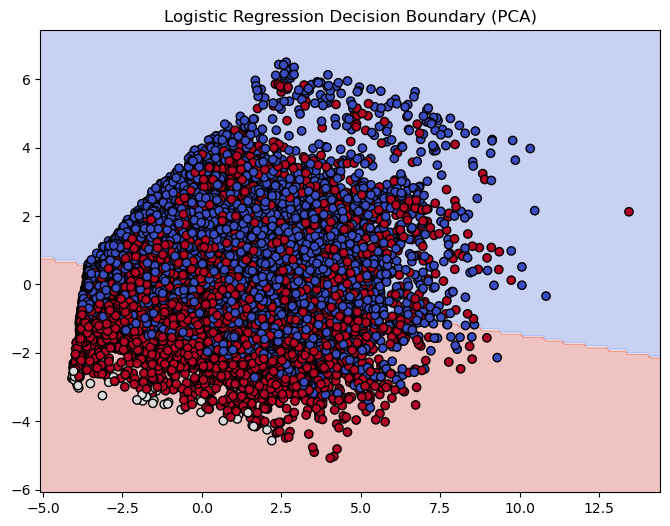

In [4]:
# Encode categorical target for PCA visualization
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
# Reduce dimensions to 2D for plotting
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
model_lr_pca = LogisticRegression(C=0.00001, max_iter=2, random_state=42).fit(X_train_pca, y_train_enc)
x_min, x_max = X_test_pca[:,0].min()-1, X_test_pca[:,0].max()+1
y_min, y_max = X_test_pca[:,1].min()-1, X_test_pca[:,1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
Z = model_lr_pca.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test_pca[:,0], X_test_pca[:,1], c=y_test_enc, cmap='coolwarm', edgecolors='k')
plt.title("Logistic Regression Decision Boundary (PCA)")
plt.show()

In [5]:
from sklearn.model_selection import GridSearchCV
print('Starting Advanced Tuning for Logistic Regression...')

param_grid_lr = {
    'C': [0.00001, 0.0001, 0.001],
    'solver': ['liblinear', 'lbfgs']
}

grid_lr = GridSearchCV(LogisticRegression(max_iter=2, random_state=42), param_grid_lr, cv=3, scoring='accuracy')
grid_lr.fit(X_train, y_train)

print(f'Best Parameters: {grid_lr.best_params_}')
tuned_pred_lr = grid_lr.best_estimator_.predict(X_test)
print(f'Tuned LR Accuracy: {accuracy_score(y_test, tuned_pred_lr):.4f}')


Starting Advanced Tuning for Logistic Regression...


Best Parameters: {'C': 0.001, 'solver': 'liblinear'}
Tuned LR Accuracy: 0.9976
